In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt

from IPython.display import display

In [12]:
import os

os.chdir(r"C:\Users\abhishek.manchala\Desktop\Sales_Dashboard")

In [ ]:
customers = pd.read_csv("../data/customers.csv")
products = pd.read_csv("data/products.csv")
orders = pd.read_csv("data/orders.csv")

In [15]:
print("CUSTOMERS DATA")
display(customers)

print("PRODUCTS DATA")
display(products)

print("ORDERS DATA")
display(orders)

CUSTOMERS DATA


,customer_id,name,city
0,1,Abhishek,Hyderabad
1,2,Rahul,Bangalore
2,3,NaN,Chennai
3,4,Sneha,NaN
4,5,Arjun,Pune
5,5,Arjun,Pune


PRODUCTS DATA


,product_id,product_name,price
0,101,Laptop,50000.0
1,102,Mobile,20000.0
2,103,Keyboard,1000.0
3,104,Mouse,NaN
4,105,Monitor,15000.0
5,105,Monitor,15000.0


ORDERS DATA


,order_id,customer_id,product_id,quantity
0,1,1,101,1.0
1,2,2,102,2.0
2,3,3,103,NaN
3,4,4,104,5.0
4,5,5,105,1.0
5,5,5,105,1.0


In [16]:
print("CUSTOMERS MISSING VALUES")
print(customers.isnull().sum())

print()

print("PRODUCTS MISSING VALUES")
print(products.isnull().sum())

print()

print("ORDERS MISSING VALUES")
print(orders.isnull().sum())

CUSTOMERS MISSING VALUES
customer_id    0
name           1
city           1
dtype: int64

PRODUCTS MISSING VALUES
product_id      0
product_name    0
price           1
dtype: int64

ORDERS MISSING VALUES
order_id       0
customer_id    0
product_id     0
quantity       1
dtype: int64


In [17]:
customers["name"] = customers["name"].fillna("Not Found")

customers["city"] = customers["city"].fillna("Not Found")

In [18]:
products["price"] = products["price"].fillna(
    products["price"].mean()
)

orders["quantity"] = orders["quantity"].fillna(
    orders["quantity"].mean()
)

In [19]:
customers.drop_duplicates(inplace=True)

products.drop_duplicates(inplace=True)

orders.drop_duplicates(inplace=True)

In [20]:
print("CLEAN CUSTOMERS")
display(customers)

print("CLEAN PRODUCTS")
display(products)

print("CLEAN ORDERS")
display(orders)

CLEAN CUSTOMERS


,customer_id,name,city
0,1,Abhishek,Hyderabad
1,2,Rahul,Bangalore
2,3,Not Found,Chennai
3,4,Sneha,Not Found
4,5,Arjun,Pune


CLEAN PRODUCTS


,product_id,product_name,price
0,101,Laptop,50000.0
1,102,Mobile,20000.0
2,103,Keyboard,1000.0
3,104,Mouse,20200.0
4,105,Monitor,15000.0


CLEAN ORDERS


,order_id,customer_id,product_id,quantity
0,1,1,101,1.0
1,2,2,102,2.0
2,3,3,103,2.0
3,4,4,104,5.0
4,5,5,105,1.0


In [21]:
customers.to_csv(
    "data/clean_customers.csv",
    index=False
)

products.to_csv(
    "data/clean_products.csv",
    index=False
)

orders.to_csv(
    "data/clean_orders.csv",
    index=False
)

print("Clean files saved successfully")

Clean files saved successfully


In [22]:
df = orders.merge(
    customers,
    on="customer_id"
)

df = df.merge(
    products,
    on="product_id"
)

display(df)

,order_id,customer_id,product_id,quantity,name,city,product_name,price
0,1,1,101,1.0,Abhishek,Hyderabad,Laptop,50000.0
1,2,2,102,2.0,Rahul,Bangalore,Mobile,20000.0
2,3,3,103,2.0,Not Found,Chennai,Keyboard,1000.0
3,4,4,104,5.0,Sneha,Not Found,Mouse,20200.0
4,5,5,105,1.0,Arjun,Pune,Monitor,15000.0


In [24]:
df["sales"] = (
    df["quantity"]
    * df["price"]
)

display(df)

,order_id,customer_id,product_id,quantity,name,city,product_name,price,sales
0,1,1,101,1.0,Abhishek,Hyderabad,Laptop,50000.0,50000.0
1,2,2,102,2.0,Rahul,Bangalore,Mobile,20000.0,40000.0
2,3,3,103,2.0,Not Found,Chennai,Keyboard,1000.0,2000.0
3,4,4,104,5.0,Sneha,Not Found,Mouse,20200.0,101000.0
4,5,5,105,1.0,Arjun,Pune,Monitor,15000.0,15000.0


In [25]:
print("Total Sales")
print(df["sales"].sum())

print()

print("Average Sales")
print(df["sales"].mean())

print()

print("Maximum Sales")
print(df["sales"].max())

Total Sales
208000.0

Average Sales
41600.0

Maximum Sales
101000.0


In [26]:
product_sales = df.groupby(
    "product_name"
)["sales"].sum()

display(product_sales)

product_name
Keyboard      2000.0
Laptop       50000.0
Mobile       40000.0
Monitor      15000.0
Mouse       101000.0
Name: sales, dtype: float64

In [27]:
city_sales = df.groupby(
    "city"
)["sales"].sum()

display(city_sales)

city
Bangalore     40000.0
Chennai        2000.0
Hyderabad     50000.0
Not Found    101000.0
Pune          15000.0
Name: sales, dtype: float64

In [28]:
conn = sqlite3.connect(
    "database.db"
)

df.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

conn.close()

print("Database Created Successfully")

Database Created Successfully


In [29]:
conn = sqlite3.connect(
    "database.db"
)

sql_df = pd.read_sql(
    "SELECT * FROM sales",
    conn
)

display(sql_df)

conn.close()

,order_id,customer_id,product_id,quantity,name,city,product_name,price,sales
0,1,1,101,1.0,Abhishek,Hyderabad,Laptop,50000.0,50000.0
1,2,2,102,2.0,Rahul,Bangalore,Mobile,20000.0,40000.0
2,3,3,103,2.0,Not Found,Chennai,Keyboard,1000.0,2000.0
3,4,4,104,5.0,Sneha,Not Found,Mouse,20200.0,101000.0
4,5,5,105,1.0,Arjun,Pune,Monitor,15000.0,15000.0


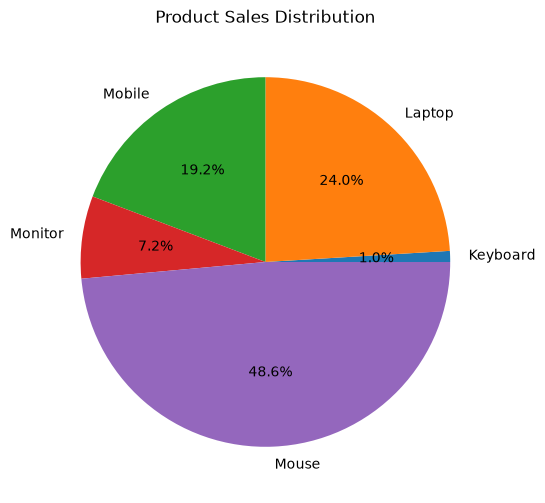

In [30]:
product_sales.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(6,6)
)

plt.title(
    "Product Sales Distribution"
)

plt.ylabel("")

plt.savefig(
    "static/charts/pie_chart.png"
)

plt.show()

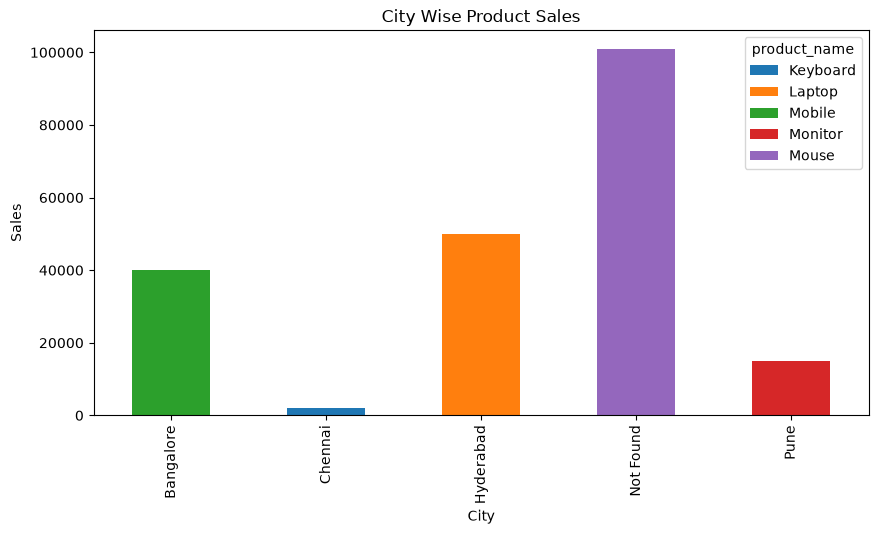

In [31]:
pivot = pd.pivot_table(
    df,
    values="sales",
    index="city",
    columns="product_name",
    aggfunc="sum",
    fill_value=0
)

pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(10,5)
)

plt.title(
    "City Wise Product Sales"
)

plt.xlabel("City")
plt.ylabel("Sales")

plt.savefig(
    "static/charts/bar_chart.png"
)

plt.show()

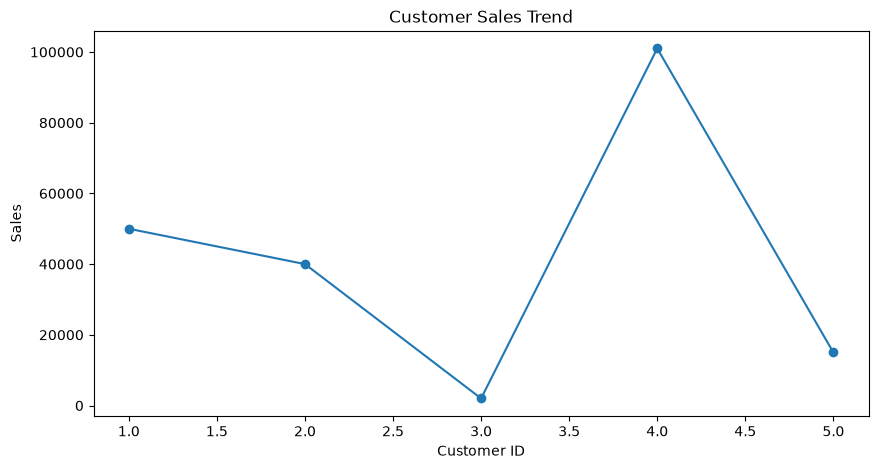

In [32]:
df.groupby(
    "customer_id"
)["sales"].sum().plot(
    kind="line",
    marker="o",
    figsize=(10,5)
)

plt.title(
    "Customer Sales Trend"
)

plt.xlabel(
    "Customer ID"
)

plt.ylabel(
    "Sales"
)

plt.savefig(
    "static/charts/line_chart.png"
)

plt.show()

In [33]:
import os

print(os.listdir("static/charts"))

['bar_chart.png', 'line_chart.png', 'pie_chart.png', 'sales_chart.png']
